# Phase 4 - Building a Linear Regression Model

In this phase we train a first, interpretable machine-learning baseline to estimate daily **Sales** for an open store. We prepare the Phase 3 features, create a reproducible train/test split, fit Linear Regression, inspect its learned equation, generate held-out predictions, visualize actual against predicted sales, and save the fitted model.

**Workflow:** Data -> Cleaning -> EDA -> Feature Engineering -> **Linear Regression** -> Evaluation -> Prediction -> Dashboard

This notebook stops at the end of Phase 4. It does not calculate evaluation scores or begin Phase 5.


## 4.1 What are we building?

The model receives one row of store/day features and returns an estimated sales value. In general, Linear Regression learns an intercept and one coefficient per input:

$$\widehat{Sales} = b_0 + b_1X_1 + b_2X_2 + \cdots + b_nX_n$$

Here, $b_0$ is the intercept, $b_i$ is the learned coefficient for feature $X_i$, and $\widehat{Sales}$ is the prediction. The model estimates these values from the training examples; we do not set them by hand.

The data and columns used below are the Rossmann `train.csv` and engineered fields from the previous phase. If you run this notebook from the `notebooks` folder, paths resolve relative to the project root.


In [74]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
PLOT_DIR = PROJECT_DIR / "plots" / "Linear regression"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
train_path = PROJECT_DIR / "data" / "train.csv"

if not train_path.exists():
    raise FileNotFoundError(f"Training data was not found: {train_path}")

df = pd.read_csv(train_path)
df_ml = df.copy()

print(f"Loaded {len(df_ml):,} rows from {train_path}")
df_ml.head()


Loaded 1,017,209 rows from e:\NIAI\Projects\Retail Sales Prediction\Database\train.csv


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,7/31/2015,5263,555,1,1,0,1
1,1,4,7/30/2015,5020,546,1,1,0,1
2,1,3,7/29/2015,4782,523,1,1,0,1
3,1,2,7/28/2015,5011,560,1,1,0,1
4,1,1,7/27/2015,6102,612,1,1,0,1


## 4.2 Prepare the modeling rows

For this first baseline, keep only observations where the store is open. Closed stores tend to have zero sales, which can make a first model appear to perform well by learning the trivial open/closed distinction instead of the sales pattern we want to study. We keep a copy so later work can still use the full dataset.

The raw `Date` is converted to a datetime and expanded into calendar features. `IsWeekend` is derived from `DayOfWeek` (Rossmann uses 1 for Monday through 7 for Sunday).


In [55]:
df_model = df_ml.copy()
df_model = df_model.loc[df_model["Open"] == 1].copy()
df_model["Date"] = pd.to_datetime(df_model["Date"], errors="raise")

df_model["Year"] = df_model["Date"].dt.year
df_model["Month"] = df_model["Date"].dt.month
df_model["Day"] = df_model["Date"].dt.day
df_model["WeekOfYear"] = df_model["Date"].dt.isocalendar().week.astype(int)
df_model["IsWeekend"] = (df_model["DayOfWeek"] >= 6).astype(int)

model_data_path = PROJECT_DIR / "data" / "df_model.csv"
df_model.to_csv(model_data_path, index=False)
print(f"Prepared modeling data saved to: {model_data_path}")

print("Modeling data shape:", df_model.shape)
print("Open values after filtering:")
print(df_model["Open"].value_counts())
df_model[["Date", "Year", "Month", "Day", "WeekOfYear", "IsWeekend"]].head()


Modeling data shape: (844392, 14)
Open values after filtering:
Open
1    844392
Name: count, dtype: int64


,Date,Year,Month,Day,WeekOfYear,IsWeekend
0,2015-07-31,2015,7,31,31,0
1,2015-07-30,2015,7,30,31,0
2,2015-07-29,2015,7,29,31,0
3,2015-07-28,2015,7,28,31,0
4,2015-07-27,2015,7,27,31,0


## 4.3 Choose features and target

A **feature** is an input the model can use; the **target** is the value we want it to predict. The first baseline uses these nine features:

| Feature | Source | Meaning in this baseline |
| --- | --- | --- |
| `Store` | Store | Store identifier, temporarily treated as numeric |
| `Customers` | Customers | Customer count for the store-day |
| `Promo` | Promo | Whether a promotion is active (0/1) |
| `SchoolHoliday` | SchoolHoliday | Whether it is a school holiday (0/1) |
| `Year` | Date | Calendar year |
| `Month` | Date | Calendar month |
| `Day` | Date | Day of the month |
| `WeekOfYear` | Date | ISO week number |
| `IsWeekend` | DayOfWeek | 1 when the day is Saturday or Sunday, otherwise 0 |

The target is `Sales`. The raw `Date` is not passed directly to the estimator because its useful calendar components have been extracted. `StateHoliday` is not included in this first feature list.


In [57]:
features = [
    "Store",
    "Customers",
    "Promo",
    "SchoolHoliday",
    "Year",
    "Month",
    "Day",
    "WeekOfYear",
    "IsWeekend",
]
target = "Sales"

print(f"Number of features: {len(features)}")
print("Features:", features)
print("Target:", target)


Number of features: 9
Features: ['Store', 'Customers', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend']
Target: Sales


## 4.4 Build `X` and `y`

`X` is the feature matrix (one row per store-day and one column per selected feature). `y` is the target series, with one sales value for each row in `X`. The row order and index are preserved so the target remains aligned with its inputs.

We check that all expected columns exist and that the selected inputs and target do not contain missing values. This notebook does not silently fill or discard missing model values.


In [58]:
missing_columns = [column for column in [*features, target] if column not in df_model.columns]
if missing_columns:
    raise KeyError(f"Required modeling columns are missing: {missing_columns}")

X = df_model[features].copy()
y = df_model[target].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Selected features or target contain missing values; resolve them before training.")

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (844392, 9)
y shape: (844392,)


## 4.5 Split into training and testing data

The model must be tested on rows it did not use to learn its coefficients. We reserve **80% for training** and **20% for testing**. `random_state=42` makes this random split repeatable; 42 is a conventional seed, not a special machine-learning value.

This is a shuffled random split, matching the introductory baseline. It is not a time-based validation strategy, so it should not be treated as proof of future-date forecasting performance.


In [79]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)
split_dir = PROJECT_DIR / "data"
split_dir.mkdir(parents=True, exist_ok=True)

X_train.to_csv(split_dir / "X_train.csv", index=True)
X_test.to_csv(split_dir / "X_test.csv", index=True)
y_train.to_frame(name=target).to_csv(split_dir / "y_train.csv", index=True)
y_test.to_frame(name=target).to_csv(split_dir / "y_test.csv", index=True)

print(f"Training and testing splits saved to: {split_dir}")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training and testing splits saved to: e:\NIAI\Projects\Retail Sales Prediction\Database
Training features: (675513, 9)
Testing features: (168879, 9)
Training target: (675513,)
Testing target: (168879,)


## 4.6 Create and train the model

`LinearRegression()` creates an unfitted estimator. Calling `.fit(X_train, y_train)` learns the coefficients and intercept from the training portion only. The test portion remains held out for the predictions and plot later in this notebook.


In [62]:
model = LinearRegression()
model


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [64]:
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ -0.18, 6.05,1463.07,..., 1.82, -2.3 , 187.82]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['Store','Customers','Promo',...,'Day','WeekOfYear','IsWeekend']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.481e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


## 4.7 Inspect the intercept

The intercept is $b_0$ in the linear equation: the model's baseline output when all feature values are zero. That combination may not represent a realistic store-day, so the intercept is primarily a mathematical part of the fitted equation, not necessarily a meaningful standalone sales forecast.


In [65]:
print(f"Intercept: {model.intercept_:,.4f}")


Intercept: -348,100.7248


## 4.8 Inspect the learned coefficients

Each coefficient is the fitted change in predicted sales associated with a one-unit increase in that feature, while other included features are held fixed. A positive value increases the linear estimate; a negative value decreases it. These are model associations, not evidence that a feature causes sales to change.

**Do not compare raw magnitudes as if all features had the same scale.** `Customers` can take values in the hundreds or thousands, while binary features only take 0 or 1. Also, `Store` is an identifier, not a true measured quantity; treating it as numeric is an intentional simplification for this first baseline.


In [66]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_,
})
coefficients["Direction"] = coefficients["Coefficient"].map(
    lambda value: "Positive" if value >= 0 else "Negative"
)
coefficients


,Feature,Coefficient,Direction
0,Store,-0.181918,Negative
1,Customers,6.049430,Positive
2,Promo,1463.067382,Positive
3,SchoolHoliday,100.585422,Positive
4,Year,173.586590,Positive
5,Month,49.906853,Positive
6,Day,1.815579,Positive
7,WeekOfYear,-2.303892,Negative
8,IsWeekend,187.815733,Positive


## 4.9 Generate predictions on the held-out rows

`model.predict(X_test)` applies the fitted equation to the test features and returns one estimate per test row. These values are not used to fit the model. The first ten estimates and a side-by-side actual/predicted table are a simple way to inspect the output format; exact agreement is not expected.


In [67]:
y_pred = model.predict(X_test)
print("First 10 predicted sales values:")
print(y_pred[:10])


First 10 predicted sales values:
[5178.47762666 7314.46195654 6746.16314124 9715.13484822 3793.17828837
 7658.68564327 6576.31667459 6802.65159432 5605.4999502  6976.25525587]


In [78]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
})
evaluation_data_path = PROJECT_DIR / "models" / "linear_regression_test_predictions.csv"
evaluation_data_path.parent.mkdir(parents=True, exist_ok=True)
comparison.to_csv(evaluation_data_path, index=False)
print(f"Held-out actual/predicted values saved to: {evaluation_data_path}")
comparison.head(10)


Held-out actual/predicted values saved to: e:\NIAI\Projects\Retail Sales Prediction\models\linear_regression_test_predictions.csv


,Actual,Predicted
378347,6782,5178.477627
866701,7675,7314.461957
114996,6669,6746.163141
10163,7355,9715.134848
548301,4533,3793.178288
638330,7721,7658.685643
655120,8151,6576.316675
490837,4404,6802.651594
136470,5600,5605.499950
947347,5707,6976.255256


## 4.10 Visualize actual versus predicted sales

The scatter plot places actual sales on the horizontal axis and predicted sales on the vertical axis. The dashed diagonal is the reference for perfect agreement. Points closer to that line have predictions closer to their observed values; this view is a visual check, not a substitute for the formal evaluation in the next phase.


Plot saved to: e:\NIAI\Projects\Retail Sales Prediction\plots\Linear regression\actual_vs_predicted_sales.png


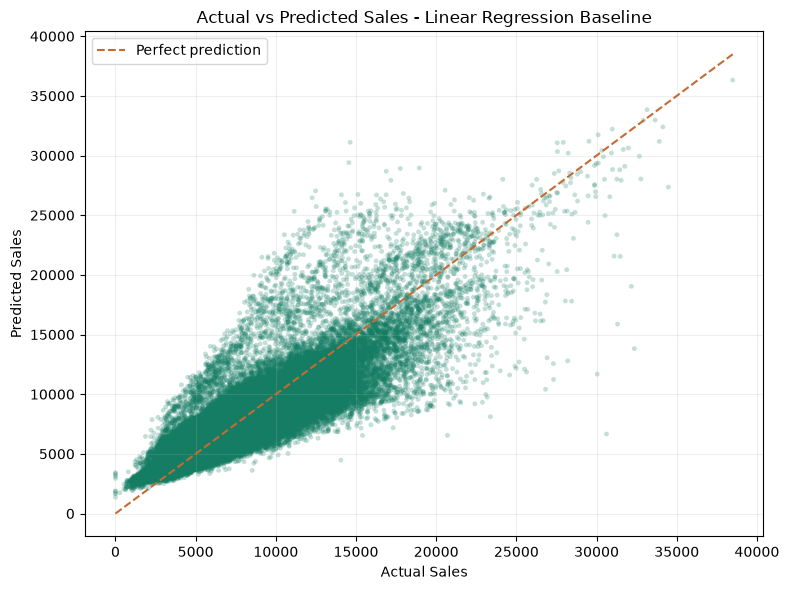

In [75]:
plot_min = min(float(y_test.min()), float(y_pred.min()))
plot_max = max(float(y_test.max()), float(y_pred.max()))

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.25, s=12, color="#147d64", edgecolors="none")
plt.plot([plot_min, plot_max], [plot_min, plot_max], "--", color="#c76a32", label="Perfect prediction")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Linear Regression Baseline")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plot_path = PLOT_DIR / "actual_vs_predicted_sales.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
print(f"Plot saved to: {plot_path}")
plt.show()


## 4.11 Save the trained model

Save the fitted estimator with `joblib` so a later script or service can load it without fitting again. The artifact is written to the project's `models` directory regardless of whether this notebook was opened from the project root or from the notebooks folder.

This file contains the estimator only. A future prediction service must also construct inputs with the same nine feature names and column order used for training.


In [76]:
model_path = PROJECT_DIR / "models" / "sales_linear_regression.pkl"
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, model_path)

print(f"Model saved to: {model_path}")
print(f"Artifact size: {model_path.stat().st_size:,} bytes")


Model saved to: e:\NIAI\Projects\Retail Sales Prediction\models\sales_linear_regression.pkl
Artifact size: 1,103 bytes


## 4.12 Verify that the saved model can be loaded

As a persistence check, load the artifact and predict the first held-out row again. This confirms that the serialized estimator can be used after the training cell has completed. It is not an additional evaluation step.


In [77]:
loaded_model = joblib.load(model_path)
reloaded_prediction = loaded_model.predict(X_test.iloc[[0]])[0]
print(f"Prediction from reloaded model: {reloaded_prediction:,.2f}")
print("Model artifact loaded successfully.")


Prediction from reloaded model: 5,178.48
Model artifact loaded successfully.


## 4.13 Initial observations and baseline limitations

Use the coefficient table and actual-versus-predicted plot to describe what this first model learned. Keep observations descriptive: coefficients show fitted relationships in this particular model and dataset; they do not establish causation.

Important limitations to carry forward:

- `Store` IDs are treated as numeric even though they are categories.
- `Customers` is an input, so a future prediction requires a customer count that is available at prediction time.
- Calendar fields such as `Month` and `WeekOfYear` are represented as ordinary numbers; they do not encode cyclic wrap-around.
- A shuffled random split can mix dates between training and testing, unlike a strict future-date test.
- Linear Regression assumes a linear additive relationship and may not capture every store, seasonal, or promotion pattern.

These choices are acceptable for a first baseline and provide clear opportunities for a later improved model.


## Phase 4 complete - stop here

At this point, the baseline has been prepared, fitted, used to produce held-out predictions, visualized, and saved as `models/sales_linear_regression.pkl`. Its held-out actual/predicted pairs are saved as `models/linear_regression_test_predictions.csv` for Phase 5. **Phase 5 has not started in this notebook:** no MAE, MSE, RMSE, R-squared, residual analysis, or baseline-versus-improved-model comparison is calculated here.
